In [1]:
print("hello world") 

hello world


In [30]:
import os

os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count())

In [3]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA 
from sklearn.cluster import KMeans
from kneed import KneeLocator 
from sklearn.metrics import silhouette_score 
from sklearn.cluster import AgglomerativeClustering 

### Data Load

In [4]:
credit_card_df = pd.read_csv("../data/clustering_data/CC_GENERAL.csv")

credit_card_df

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8945,C19186,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6
8946,C19187,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,NaN,0.000000,6
8947,C19188,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6
8948,C19189,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6


In [5]:
credit_card_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

### Data Preprocessing 

In [6]:
credit_card_df.isnull().sum() 

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

In [7]:
# handling missing values 

credit_card_df['CREDIT_LIMIT'] = credit_card_df['CREDIT_LIMIT'].fillna(credit_card_df['CREDIT_LIMIT'].median())

simple = SimpleImputer(strategy='mean')
credit_card_df[['MINIMUM_PAYMENTS']] = simple.fit_transform(credit_card_df[['MINIMUM_PAYMENTS']]) 

credit_card_df.isnull().sum() 

CUST_ID                             0
BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              0
CASH_ADVANCE_TRX                    0
PURCHASES_TRX                       0
CREDIT_LIMIT                        0
PAYMENTS                            0
MINIMUM_PAYMENTS                    0
PRC_FULL_PAYMENT                    0
TENURE                              0
dtype: int64

### Explore Data Analysis (EDA)

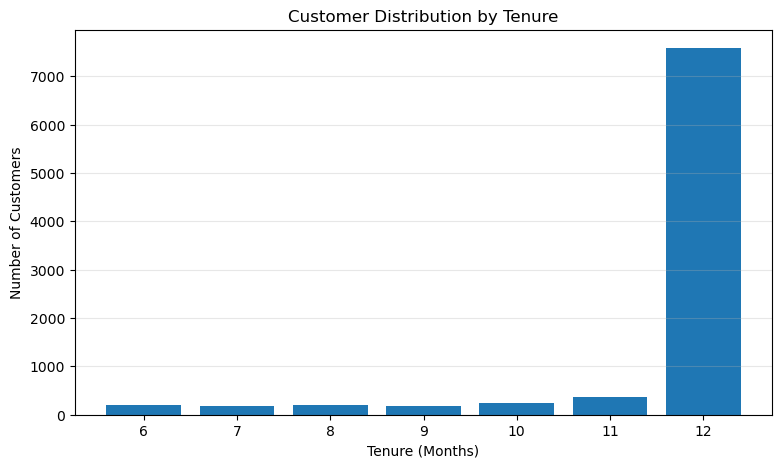

In [8]:
tenure = credit_card_df['TENURE'].value_counts() 

plt.figure(figsize = (9, 5))
plt.bar(tenure.index, tenure.values) 
plt.title("Customer Distribution by Tenure") 
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers") 

plt.xticks(tenure.index)
plt.grid(axis = 'y', alpha = 0.3)
plt.show() 

- Maximum customer's tenure is 12 months 

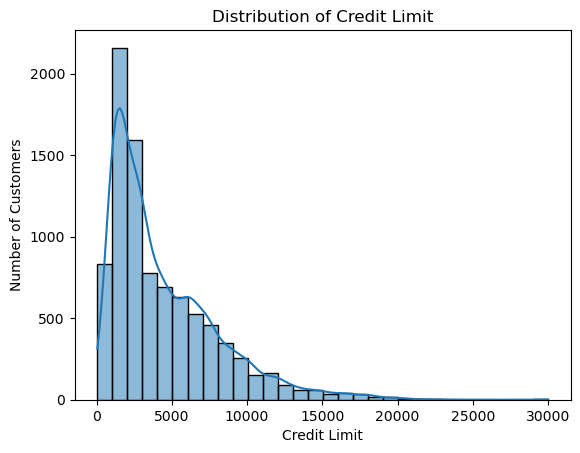

In [9]:
sns.histplot(data = credit_card_df, x = 'CREDIT_LIMIT', bins = 30, kde = True) 
plt.title("Distribution of Credit Limit") 
plt.xlabel("Credit Limit") 
plt.ylabel("Number of Customers") 
plt.show() 


- The credit card limit is 3000 highly.

In [10]:
# drop unwanted col 

clean_df = credit_card_df.drop(columns = ['CUST_ID'], axis = 1) 

clean_df.columns

Index(['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES',
       'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY',
       'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY',
       'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX',
       'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT',
       'TENURE'],
      dtype='object')

<Axes: >

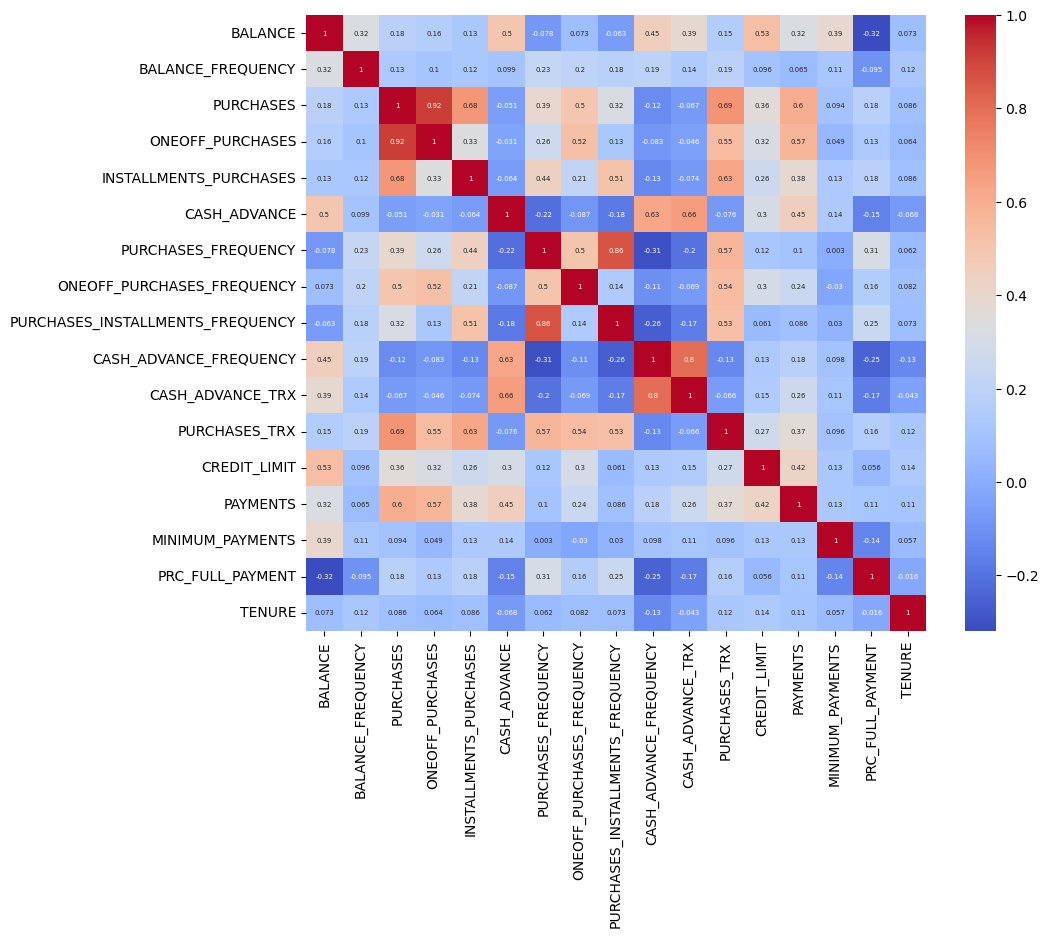

In [11]:
plt.figure(figsize = (10, 8))
correlation_map = clean_df.corr(numeric_only = True)

sns.heatmap(correlation_map, annot = True, annot_kws = {'size' : 5}, cmap = 'coolwarm')

### Feature Scaling

In [12]:
X = clean_df

In [13]:
X.shape

(8950, 17)

In [14]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X) 

X_scaled

array([[-0.73198937, -0.24943448, -0.42489974, ..., -0.31096755,
        -0.52555097,  0.36067954],
       [ 0.78696085,  0.13432467, -0.46955188, ...,  0.08931021,
         0.2342269 ,  0.36067954],
       [ 0.44713513,  0.51808382, -0.10766823, ..., -0.10166318,
        -0.52555097,  0.36067954],
       ...,
       [-0.7403981 , -0.18547673, -0.40196519, ..., -0.33546549,
         0.32919999, -4.12276757],
       [-0.74517423, -0.18547673, -0.46955188, ..., -0.34690648,
         0.32919999, -4.12276757],
       [-0.57257511, -0.88903307,  0.04214581, ..., -0.33294642,
        -0.52555097, -4.12276757]])

### Visulizing the Data 

In [15]:
pca = PCA(n_components = 3) 

X_pca = pca.fit_transform(X_scaled) 

Text(0.5, 0.92, '3d Projection')

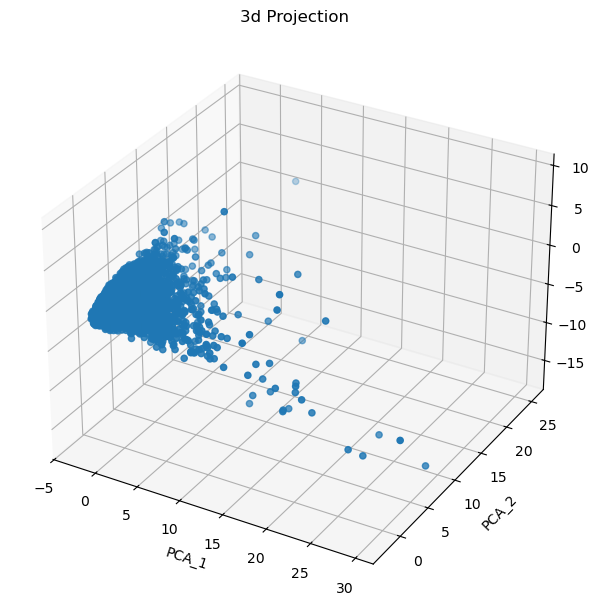

In [16]:
fig = plt.figure(figsize = (8, 6)) 

ax = fig.add_subplot(111, projection = '3d') 

ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2]) 

ax.set_xlabel("PCA_1") 
ax.set_ylabel("PCA_2")
ax.set_zlabel("PCA_3") 

plt.tight_layout()
ax.set_title("3d Projection") 

In [17]:
print(pca.explained_variance_ratio_)

[0.27290311 0.20302058 0.08791861]


### Choosing K with (elbow & silhouette Score) 

#### Elbow method

In [31]:
wcss = [] 

for k in range(1, 11):
    kmeans = KMeans(n_clusters = k, random_state = 42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_) 

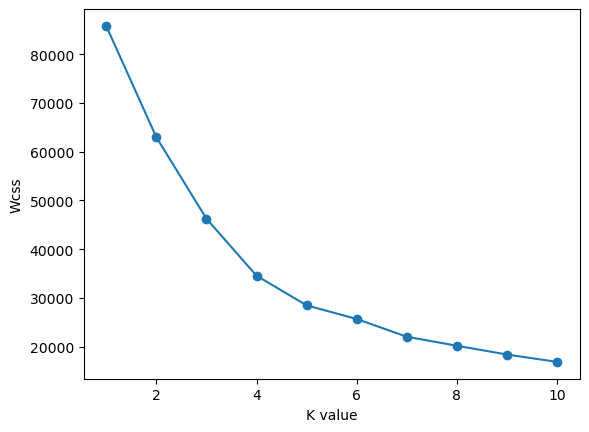

In [19]:
plt.plot(range(1, 11), wcss, marker = 'o')
plt.xlabel("K value")
plt.ylabel("Wcss")
plt.show() 

- __It highlight best K is 4__

In [20]:
## using Kneelocator 

knee = KneeLocator(range(1, 11), wcss, curve = 'convex', direction = 'decreasing') 

optimal_k_value = knee.elbow

print("Best K Value:- ", optimal_k_value) 

Best K Value:-  4


#### Silhouette Score

In [21]:
scores = [] 

for k in range(2, 11):
    kmens = KMeans(n_clusters = k, random_state = 42) 
    labels = kmens.fit_predict(X_pca)
    score = silhouette_score(X_pca, labels) 
    scores.append(score) 
    

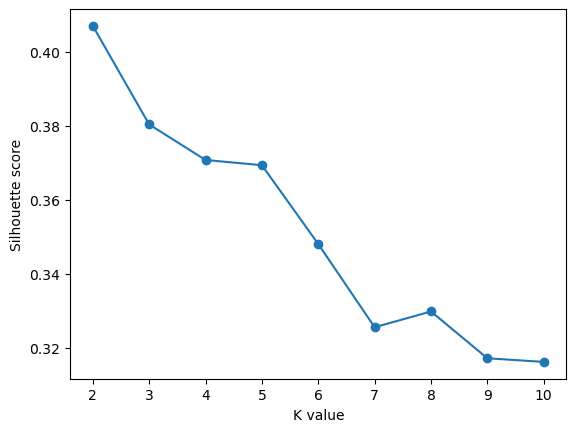

In [22]:
plt.plot(range(2, 11), scores, marker = 'o') 
plt.xlabel("K value") 
plt.ylabel("Silhouette score") 
plt.show() 

### K-Means Clustering 

Text(0.5, 0.92, '3d Projection')

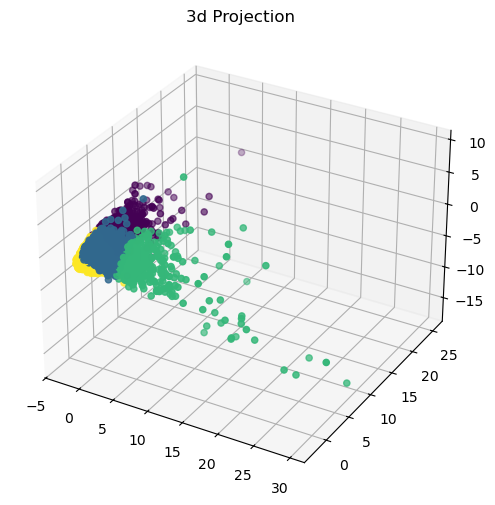

In [23]:
kmeans = KMeans(n_clusters = 4, random_state = 42) 
label_kmeans = kmeans.fit_predict(X_pca) 

fig = plt.figure(figsize = (8, 6))

ax = fig.add_subplot(111, projection = '3d')

ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c = label_kmeans)

ax.set_title("3d Projection") 

### Agglomerative Clustering 

Text(0.5, 0.92, '3d Projection')

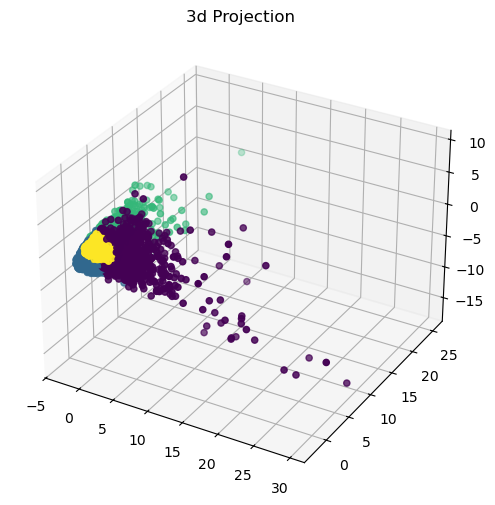

In [24]:
agg = AgglomerativeClustering(n_clusters = 4, linkage = 'ward')
labels_agg = agg.fit_predict(X_pca)

fig = plt.figure(figsize = (8, 6))

ax = fig.add_subplot(111, projection  = '3d')

ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c = labels_agg)

ax.set_title("3d Projection") 

- This graph separete the 4 clusters clearly so that why I perfer this chart "Agglomerative clustering". 

In [25]:
# Create a dataframe containing customer information and cluster labels

segment_results = credit_card_df.copy()

segment_results["Cluster_ID"] = labels_agg

# Selecting important financial features for customer profiling
profile_columns = [
    "BALANCE",
    "PURCHASES",
    "PURCHASES_FREQUENCY",
    "CASH_ADVANCE",
    "CASH_ADVANCE_FREQUENCY",
    "CREDIT_LIMIT",
    "PAYMENTS",
    "PRC_FULL_PAYMENT",
    "PURCHASES_TRX"
]

# Calculateing median financial behaviour for each cluster
cluster_profile = (segment_results.groupby("Cluster_ID")[profile_columns].median())


# Calculateing customer count and percentage
cluster_profile.insert(0, "Customer_Count", segment_results.groupby("Cluster_ID").size())

cluster_profile["Customer_Percentage"] = (cluster_profile["Customer_Count"]) / len(segment_results) * 100

# Display cluster profiles
display(cluster_profile.round(2))

,Customer_Count,BALANCE,PURCHASES,PURCHASES_FREQUENCY,CASH_ADVANCE,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,PURCHASES_TRX,Customer_Percentage
Cluster_ID,,,,,,,,,,,
0,1083,2070.63,3408.01,1.00,0.00,0.00,7500.0,3291.57,0.00,45.0,12.10
1,4821,613.81,182.80,0.25,0.00,0.00,2500.0,574.51,0.00,3.0,53.87
2,1310,3530.38,0.00,0.00,3269.98,0.42,6000.0,1646.79,0.00,0.0,14.64
3,1736,208.25,717.71,1.00,0.00,0.00,2500.0,719.94,0.08,16.0,19.40


In [26]:
# Assing the customer with there behaviours 

cluster_config = {
    0: {
        "name": "Frequent Spenders",
        "description": "Customers with frequent purchases and higher spending.",
        "icon": "🛍️"
    },

    1: {
        "name": "Low Usage Customers",
        "description": "Customers with relatively low purchase activity.",
        "icon": "💳"
    },

    2: {
        "name": "Cash Advance Users",
        "description": "Customers who frequently use credit-card cash advances.",
        "icon": "💵"
    },

    3: {
        "name": "Active Low-Balance Customers",
        "description": "Customers who buy regularly but keep low outstanding balances.",
        "icon": "👛"
    }
}

In [27]:
segment_results["Segment_Name"] = (
    segment_results["Cluster_ID"]
    .map(lambda x: cluster_config[x]["name"])
)

segment_results["Segment_Description"] = (
    segment_results["Cluster_ID"]
    .map(lambda x: cluster_config[x]["description"])
)

In [28]:
import os

# Createing output directory
os.makedirs("data/processed", exist_ok=True)

# Save customer-level segmentation results
segment_results.to_csv("data/processed/customer_segments.csv",index=False)

# Createing the summary for dashboard
segment_summary = (
    segment_results
    .groupby(["Cluster_ID", "Segment_Name", "Segment_Description"])
    .agg(
        Customer_Count=("CUST_ID", "count"),
        Median_Balance=("BALANCE", "median"),
        Median_Purchases=("PURCHASES", "median"),
        Median_Cash_Advance=("CASH_ADVANCE", "median"),
        Median_Purchase_Frequency=("PURCHASES_FREQUENCY", "median")
    )
    .reset_index()
)

segment_summary["Customer_Percentage"] = (segment_summary["Customer_Count"] / len(segment_results)) * 100

segment_summary.to_csv("data/processed/segment_summary.csv", index=False)

print("Customer segmentation files exported successfully!")

Customer segmentation files exported successfully!


In [35]:
import os 
import joblib
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.pipeline import Pipeline 

segment_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=3)), 
    ("knn", KNeighborsClassifier(n_neighbors = 5))
])

segment_pipeline.fit(X, labels_agg)
print("Agrement with Agglormerative Lables:- ", segment_pipeline.score(X, labels_agg))

joblib.dump({
    "model" : segment_pipeline,
    "features" : list(X.columns),
    "cluster_config" : cluster_config,
    "fill_values" : { "CREDIT_LIMIT" : float(credit_card_df['CREDIT_LIMIT'].median()),
                      "MINIMUM_PAYMENTS" : float(simple.statistics_[0]),
                    },
}, "segment_model.joblib")
print("Saved")



Agrement with Agglormerative Lables:-  0.9964245810055866
Saved
